# Presión fiscal y desigualdad de la renta

In [ ]:
# Parámetros de la gráfica
SLUG = "economia"  # carpeta en research/temas/
GRAFICA_ID = "presion-fiscal-redistribucion"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Presión fiscal y desigualdad de la renta"  # `titulo` de la gráfica en config.json
DESDE = 1976  # primer año candidato (METODOLOGIA §2.3)
UNIVERSO = "ocde"  # ocde | ue27: todos sus países con dato en los dos ejes (METODOLOGIA §2.6)
EJE_X = {"titulo": "Presión fiscal", "unidad": "% del PIB"}
EJE_Y = {"titulo": "Desigualdad de la renta disponible (índice de Gini)", "unidad": "índice de Gini (de 0 a 100)"}
ANIOS = None  # (desde, hasta) si el config fija una ventana; None = último año común de cada país
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

Cada punto es un país de la OCDE con dato en los dos ejes.

- **Eje horizontal:** la **presión fiscal**, impuestos y cotizaciones sociales en porcentaje del PIB (el mismo indicador que la gráfica `presion-fiscal` de Fiscalidad), del mismo año que el eje vertical.
- **Eje vertical:** la **desigualdad de la renta disponible** (después de impuestos directos y prestaciones monetarias), medida con el índice de Gini de 0 (todas las personas con la misma renta) a 100 (toda la renta en una sola persona), para el conjunto de la población (el mismo indicador que la gráfica `gini-renta-disponible`).

**Para qué sirve.** Es la otra lectura de la presión fiscal: quienes defienden una presión fiscal alta sostienen que financia la redistribución de la renta, algo que no aparece cuando solo se compara con el crecimiento de la economía o de las empresas (`presion-fiscal-crecimiento`, `presion-fiscal-empresas-alto-crecimiento`). Quienes proponen bajarla sostienen que lo relevante es el crecimiento. **La relación entre dos indicadores no muestra que uno cause el otro**: no se dibuja línea de tendencia ni se calcula la correlación.

**Limitaciones.**
- El nivel de desigualdad después de impuestos depende también de lo desigual que sea la renta de mercado (antes de impuestos y prestaciones), que varía mucho entre países. Por eso las notas dan también cuánto reducen la desigualdad los impuestos directos y las prestaciones en España (Gini de mercado menos Gini disponible).
- Solo recoge impuestos directos y prestaciones monetarias: no incluye el efecto de los servicios públicos (sanidad, educación) ni el de los impuestos indirectos como el IVA.

## 2. Descarga

- **OCDE, Revenue Statistics** (`OECD.CTP.TPS,DSD_REV_COMP_OECD@DF_RSOECD`, versión 2.0): ingresos fiscales totales (`TAX_REV`, `S13`, `_T`) en % del PIB.
- **OCDE, Income Distribution Database** (`OECD.WISE.INE,DSD_WISE_IDD@DF_IDD`, versión 1.0): índice de Gini de la renta disponible (`INC_DISP_GINI`) y, para las notas, de la renta de mercado (`INC_MRKT_GINI`), población total (`AGE=_T`), metodología de 2012 (`METH2012`) y definición vigente (`D_CUR`); también para la población de 18 a 65 años (`Y18T65`), solo para las notas.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.paises import paises_de
from lib.writer import construir_dispersion_data, write_dispersion_data

PAISES = paises_de(UNIVERSO)

from datetime import date

from lib import eurostat, oecd
from lib.paises import nombre_punto
from lib.tipos import FuenteMeta

AREAS = {c: c for c in PAISES}  # todos los países del universo, con su código como clave de serie
HOY = date.today().isoformat()

# Presión fiscal (OCDE, Revenue Statistics): la misma que fiscalidad/presion-fiscal
DATAFLOW_REV = "OECD.CTP.TPS,DSD_REV_COMP_OECD@DF_RSOECD,2.0"
CLAVE_REV = "{AREA}.TAX_REV.S13._T._T.PT_B1GQ.A"
DATAFLOW_IDD = "OECD.WISE.INE,DSD_WISE_IDD@DF_IDD,1.0"
# Dimensiones: país . frecuencia . medida . operación estadística . unidad . edad . metodología . definición . umbral de pobreza
def clave_gini(medida, edad):
    return "{AREA}.A." + f"{medida}._Z.0_TO_1.{edad}.METH2012.D_CUR._Z"


x, _ = oecd.get(DATAFLOW_REV, CLAVE_REV, areas=AREAS, desde=DESDE)
mercado, _ = oecd.get(DATAFLOW_IDD, clave_gini("INC_MRKT_GINI", "_T"), areas=AREAS, desde=DESDE)
disponible, _ = oecd.get(DATAFLOW_IDD, clave_gini("INC_DISP_GINI", "_T"), areas=AREAS, desde=DESDE)
mercado_act, _ = oecd.get(DATAFLOW_IDD, clave_gini("INC_MRKT_GINI", "Y18T65"), areas=AREAS, desde=DESDE)
disponible_act, _ = oecd.get(DATAFLOW_IDD, clave_gini("INC_DISP_GINI", "Y18T65"), areas=AREAS, desde=DESDE)
media_x, _ = oecd.get(DATAFLOW_REV, CLAVE_REV, areas={"OECD_REP": "OECD_REP", "OECD": "OECD"}, desde=DESDE)
print("Países con presión fiscal:", x["serie"].nunique(), "· con Gini de mercado y disponible:", len(set(mercado["serie"]) & set(disponible["serie"])))

Países con presión fiscal: 38 · con Gini de mercado y disponible: 37


## 3. Transformación

1. **Desigualdad de la renta disponible** = índice de Gini de la renta disponible multiplicado por 100 (la OCDE lo publica de 0 a 1).
2. El escritor elige para cada país el último año con dato en los dos ejes, el mismo para `x` e `y`.
3. **Sin punto de medias:** la OCDE no publica el índice de Gini de la OCDE ni de la UE-27 en la IDD (se comprueba en la descarga).
4. Para las notas: la reducción de la desigualdad (Gini de mercado − Gini disponible) de España, para la población total y para la de 18 a 65 años, y su puesto entre los países.

In [ ]:
def unir(xs):
    xs = [str(x) for x in xs]
    return xs[0] if len(xs) == 1 else f"{', '.join(xs[:-1])} y {xs[-1]}"


def es(v, d=1):
    return estilos.formato_es(v, d)


def diferencia(mercado, disponible):
    """Gini de mercado − Gini disponible, por país y año, en puntos de Gini sobre 100."""
    m = mercado.set_index(["serie", "periodo"])["valor"]
    d = disponible.set_index(["serie", "periodo"])["valor"]
    comunes = m.index.intersection(d.index)
    s = (m[comunes] - d[comunes]) * 100
    return s.rename("valor").reset_index()


assert set(mercado["serie"]).isdisjoint({"OECD", "EU27_2020"}), "La IDD publica una media: revisar si se añade el punto"
y = disponible.assign(valor=disponible["valor"] * 100)[["serie", "periodo", "valor"]]
reduccion = diferencia(mercado, disponible)
y_act = diferencia(mercado_act, disponible_act)

_, FLUJO_REV, VERSION_REV = DATAFLOW_REV.split(",")
_, FLUJO_IDD, VERSION_IDD = DATAFLOW_IDD.split(",")
fuentes = [
    FuenteMeta("eje_x", oecd.ORGANISMO, f"{FLUJO_REV} (Revenue Statistics, versión {VERSION_REV}): TAX_REV, S13, _T (TOTALTAX), PT_B1GQ", oecd.URL_EXPLORER, HOY),
    FuenteMeta("eje_y", oecd.ORGANISMO, f"{FLUJO_IDD} (Income Distribution Database, versión {VERSION_IDD}): INC_DISP_GINI, _T, METH2012, D_CUR (INC_MRKT_GINI, solo para las notas)", oecd.URL_EXPLORER, HOY),
]

# Cifras de España para las notas: población total frente a 18-65 años, en el año del punto
puntos = construir_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=[],
    generado_por="", desde=DESDE, anios=ANIOS,
)["puntos"]
a_esp = next(p["anio"] for p in puntos if p["codigo"] == "ESP")
esp_gini = next(p["y"] for p in puntos if p["codigo"] == "ESP")
red = reduccion.set_index(["serie", "periodo"])["valor"]
esp_total = red.get(("ESP", a_esp))
act = y_act.set_index(["serie", "periodo"])["valor"]
esp_act = act.get(("ESP", a_esp))
# Posición de España entre los países con dato de las dos poblaciones (en el año de cada punto)
rangos = []
for p in puntos:
    v = act.get((p["codigo"], p["anio"]))
    t = red.get((p["codigo"], p["anio"]))
    if v is not None and t is not None:
        rangos.append((p["codigo"], t, v))
n_total = len(rangos)
pos_total = 1 + sum(1 for _, t, _ in rangos if t > esp_total)
pos_act = 1 + sum(1 for _, _, a in rangos if a > esp_act)

NOTAS = [
    f"Presión fiscal: OCDE, Revenue Statistics ({FLUJO_REV}, versión {VERSION_REV}): impuestos y cotizaciones sociales "
    "obligatorias de las administraciones públicas, en porcentaje del PIB.",
    f"Desigualdad: OCDE, Income Distribution Database ({FLUJO_IDD}, versión {VERSION_IDD}): índice de Gini de la renta "
    "disponible equivalente (después de impuestos directos y prestaciones monetarias), población total, metodología de "
    "2012; de 0 a 100 (la OCDE publica el índice de 0 a 1).",
    "El nivel de desigualdad después de impuestos depende también de la desigualdad de la renta de mercado (antes de "
    "impuestos y prestaciones), que varía mucho entre países.",
    f"Cuánto la reducen los impuestos directos y las prestaciones (Gini de mercado menos Gini disponible): en España en "
    f"{a_esp}, {es(esp_total)} puntos para la población total y {es(esp_act)} para la de 18 a 65 años; entre los "
    f"{n_total} países con dato en las dos poblaciones, España ocupa el puesto {pos_total} de {n_total} con la población "
    f"total y el {pos_act} con la de 18 a 65 años (de más a menos reducción). Las pensiones públicas cuentan como "
    "transferencias, no como renta de mercado, así que en los países con más personas jubiladas la reducción es mayor "
    "por ese motivo.",
    "No incluye el efecto de los servicios públicos (sanidad, educación) ni el de los impuestos indirectos como el IVA.",
    "Sin punto de la media OCDE ni de la UE-27: la IDD no publica el índice de Gini para esos agregados.",
]

## 4. Visualización

Un punto por país, sin línea de tendencia ni correlación (METODOLOGIA §2.6).

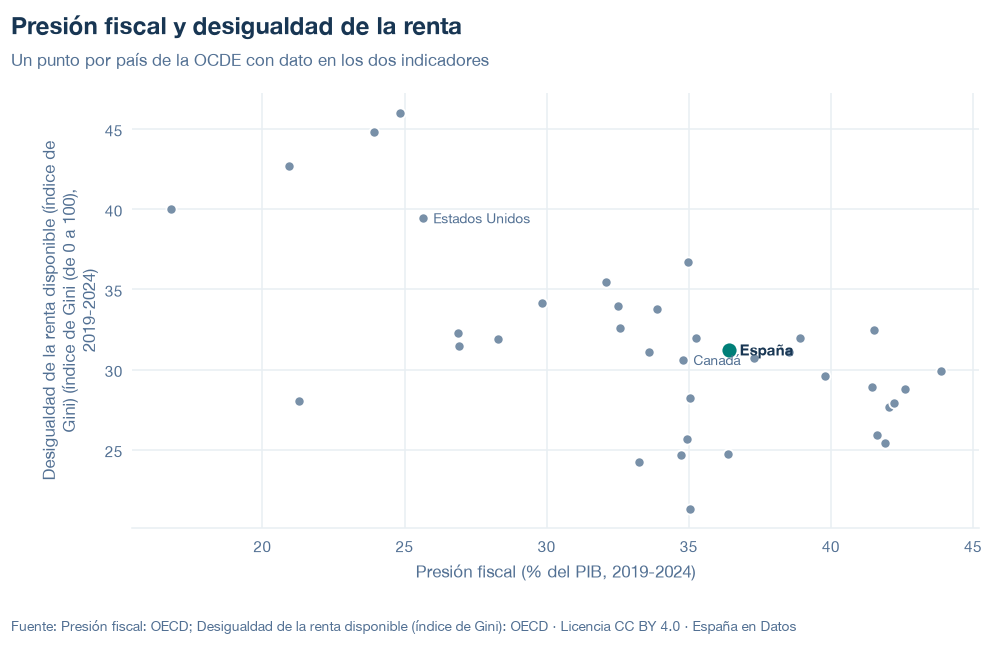

codigo  anio         x         y
   AUS  2020 28.292731 31.900000
   AUT  2023 42.610018 28.820488
   BEL  2023 41.891726 25.408104
   CAN  2023 34.785133 30.599999
   CHE  2023 26.898372 31.464326
   CHL  2022 23.910947 44.814755
   CRI  2024 24.840079 46.022090
   CZE  2023 33.242523 24.242426
   DEU  2023 37.294771 30.700001
   DNK  2022 42.054919 27.640000
   ESP  2023 36.414221 31.243214
   EST  2023 33.597961 31.116071
   FIN  2024 42.217254 27.945000
   FRA  2023 43.854973 29.899999
   GBR  2023 34.965313 36.703035
   GRC  2023 38.922829 31.955937
   HUN  2023 35.029253 28.233457
   IRL  2023 21.285333 28.063530
   ISL  2019 34.717066 24.679494
   ISR  2023 29.833744 34.154999
   ITA  2023 41.523746 32.474399
   JPN  2021 33.877709 33.800000
   KOR  2023 26.871141 32.300001
   LTU  2023 32.081225 35.482571
   LUX  2023 39.808539 29.627606
   LVA  2023 32.508562 33.994633
   MEX  2022 16.764848 40.011190
   NLD  2024 38.541274 31.099999
   NOR  2023 41.630843 25.900000
   NZL  20

In [ ]:
datos = construir_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
)
fig = estilos.figura(datos, titulo=TITULO)
estilos.mostrar(fig)
print(pd.DataFrame(datos["puntos"]).to_string(index=False))

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web (`codigo;pais;anio;eje_x;eje_y`).

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/presion-fiscal-redistribucion.json y data/presion-fiscal-redistribucion.csv


## 6. Fuentes, notas y licencia

- OCDE, Revenue Statistics: `OECD.CTP.TPS,DSD_REV_COMP_OECD@DF_RSOECD,2.0` (`TAX_REV`, `S13`, `_T`, `PT_B1GQ`).
- OCDE, Income Distribution Database: `OECD.WISE.INE,DSD_WISE_IDD@DF_IDD,1.0` (`INC_DISP_GINI`; `INC_MRKT_GINI`, solo para las notas; `_T` y `Y18T65`, `METH2012`, `D_CUR`).

La fecha de consulta de cada eje está en `fuentes` del JSON; las notas incluyen los países sin dato y la advertencia de que la relación no muestra causa.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.